In [1]:
from pathlib import Path
import sys
import yaml

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn

project_root = Path.cwd().resolve()
if not (project_root / 'src').exists():
    project_root = project_root.parent

sys.path.insert(0, str(project_root))

from src.data import drop_outliers
from src.experiments import RANDOM_STATE, cv, load_features, run_study
from src.features import clean_data, add_features, encode_quality
from src.nn import cross_validate_mlp, fit_mlp
from src.preprocessing import build_preprocessor

# Загрузка и обработка данных

In [2]:
config_path = project_root / "config.yaml"
with config_path.open(encoding="utf-8") as file:
    config = yaml.safe_load(file)

train = pd.read_csv(project_root / config["data"]["train_path"])

In [3]:
train_data = clean_data(train)
train_data = add_features(train_data)
train_data = encode_quality(train_data)
train_data = drop_outliers(train_data)

In [4]:
numeric_features, categorical_features = load_features(train_data)
X_train = train_data[numeric_features + categorical_features]
y_train = np.log1p(train_data["SalePrice"])

# Подбор оптимальных гиперпараметров нейросети

In [5]:
HIDDEN_DIMS = {
    "16": (16,),
    "32": (32,),
    "64": (64,),
    "128": (128,),
    "256": (256,),
    "128_64": (128, 64),
    "256_128": (256, 128),
    "256_128_64": (256, 128, 64),
}

ACTIVATIONS = {
    "relu": nn.ReLU,
    "gelu": nn.GELU,
    "leaky_relu": nn.LeakyReLU,
    "tanh": nn.Tanh,
}

OPTIMIZERS = {
    "adam": torch.optim.Adam,
    "adamw": torch.optim.AdamW,
}


def objective_mlp(trial):
    hidden_name = trial.suggest_categorical("hidden_dims", list(HIDDEN_DIMS.keys()))
    activation_name = trial.suggest_categorical("activation", list(ACTIVATIONS.keys()))
    optimizer_name = trial.suggest_categorical("optimizer_cls", list(OPTIMIZERS.keys()))

    params = {
        "lr": trial.suggest_float("lr", 1e-4, 1e-2, log=True),
        "hidden_dims": HIDDEN_DIMS[hidden_name],
        "activation": ACTIVATIONS[activation_name],
        "optimizer_cls": OPTIMIZERS[optimizer_name],
        "dropout": trial.suggest_float("dropout", 0.0, 0.5),
        "batchnorm": trial.suggest_categorical("batchnorm", [True, False]),
        "cosine": trial.suggest_categorical("cosine", [True, False]),
        "batch_size": trial.suggest_categorical("batch_size", [16, 32, 64, 128]),
    }
    return cross_validate_mlp(
        X_train, y_train, numeric_features, categorical_features, cv, **params
    ).mean()


study_mlp = run_study(objective_mlp, "MLP hyperparameters search", n_trials=50, params_key="mlp")

  0%|          | 0/50 [00:00<?, ?it/s]

Best CV accuracy: 0.1127
Best params: {'hidden_dims': '256_128', 'activation': 'gelu', 'optimizer_cls': 'adam', 'lr': 0.00011832481805701787, 'dropout': 0.4994535861772102, 'batchnorm': False, 'cosine': True, 'batch_size': 16}


# Кривые обучения на одном разбиении

Берём лучший набор гиперпараметров из optuna

In [6]:
best_params = study_mlp.best_params.copy()
best_params["activation"] = ACTIVATIONS[best_params["activation"]]
best_params["optimizer_cls"] = OPTIMIZERS[best_params["optimizer_cls"]]
best_params["hidden_dims"] = HIDDEN_DIMS[best_params["hidden_dims"]]

In [7]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=RANDOM_STATE
)

preprocessor = build_preprocessor(numeric_features, categorical_features)
X_tr = preprocessor.fit_transform(X_tr)
X_val = preprocessor.transform(X_val)

model_nn, history = fit_mlp(X_tr, y_tr, X_val, y_val, random_state=RANDOM_STATE, **best_params)

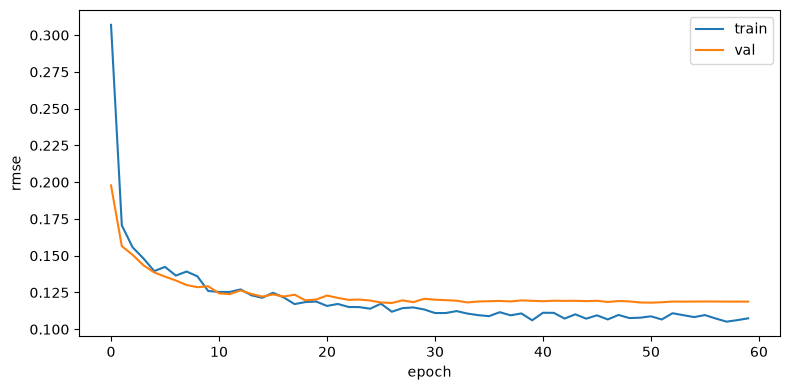

In [8]:
fig, ax = plt.subplots(1, 1, figsize=(8, 4))

ax.plot(history['train_rmse'], label='train')
ax.plot(history['val_rmse'], label='val')
ax.set_xlabel('epoch')
ax.set_ylabel('rmse')
ax.legend()

plt.tight_layout()
plt.show()